# Figure 5 — publication plotting

This notebook reads only the validated tables produced by the analysis
notebook. It exports four analytical panels and a complete assembled figure in
PNG, SVG/PDF panel files, and TIFF. Styling matches Figures 1–4.


In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    os.environ.get("MITOXY_PROJECT_ROOT", "/scratch/ar58064/mitoxy")
).resolve()
REFERENCE_DIR = PROJECT_ROOT / "data" / "reference" / "figure_5"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "figure_5_clean"
FIGURE_DIR = PROJECT_ROOT / "figures" / "figure_5_clean"
for directory in [REFERENCE_DIR, OUTPUT_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from PIL import Image as PILImage, ImageChops

BLUE = "#087EBD"
ORANGE = "#E36A00"
TEAL = "#00A67E"
PURPLE = "#8053A6"
DARK = "#202832"
MID = "#667386"
GRID = "#DDE3E9"
BAND = "#F2F5F8"
WHITE = "#FFFFFF"

mpl.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 13,
    "axes.labelcolor": DARK, "text.color": DARK,
    "xtick.color": "#4E5968", "ytick.color": DARK,
    "axes.linewidth": 1.1, "figure.facecolor": WHITE,
    "axes.facecolor": WHITE, "savefig.facecolor": WHITE,
    "svg.fonttype": "none", "pdf.fonttype": 42,
})

def p_text(value):
    return f"{value:.1e}" if value < 0.001 else f"{value:.3f}"

def panel_letter(fig, letter):
    fig.text(0.025, 0.965, letter, fontsize=34, fontweight="bold",
             color=DARK, ha="left", va="top")

def clean_axes(ax, grid="x"):
    ax.grid(axis=grid, color=GRID, linewidth=1)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_color("#8B96A3")
    ax.spines["bottom"].set_color("#8B96A3")

def save_panel(fig, stem):
    paths = {}
    for suffix in ["png", "svg", "pdf"]:
        path = FIGURE_DIR / f"{stem}.{suffix}"
        fig.savefig(path, dpi=400, bbox_inches="tight", pad_inches=0.12)
        paths[suffix] = path
    return paths

def read_panel(stem):
    path = OUTPUT_DIR / stem
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {path}. Run 01_Figure5_Analysis.ipynb first."
        )
    return pd.read_csv(path)

panel_a = read_panel("panel_a_compartment_localization.csv")
panel_b = read_panel("panel_b_cross_cohort_coupling.csv")
panel_c = read_panel("panel_c_adjusted_coupling.csv")
panel_d = read_panel("panel_d_spatial_replication.csv")


Project root: /scratch/ar58064/mitoxy


## Panel A — single-cell compartment localization


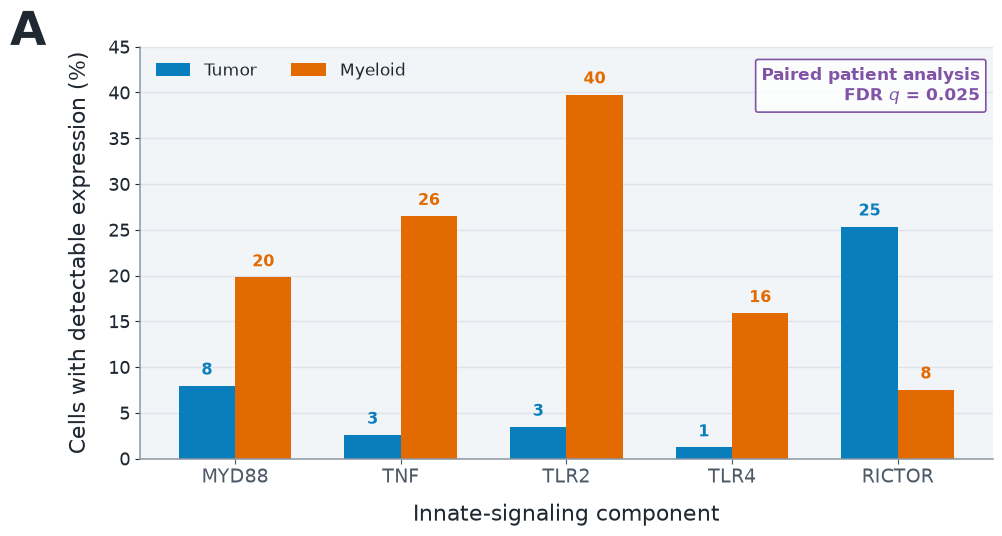

In [2]:
fig, ax = plt.subplots(figsize=(10.4, 5.8))
x = np.arange(len(panel_a))
width = 0.34
ax.axhspan(0, 45, color=BAND, zorder=0)

bars_t = ax.bar(x - width/2, panel_a["tumor_detection_pct"], width,
                color=BLUE, label="Tumor", zorder=2)
bars_m = ax.bar(x + width/2, panel_a["myeloid_detection_pct"], width,
                color=ORANGE, label="Myeloid", zorder=2)
for bars, color in [(bars_t, BLUE), (bars_m, ORANGE)]:
    for bar in bars:
        value = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, value + 0.8, f"{value:.0f}",
                ha="center", va="bottom", fontsize=11.5,
                fontweight="bold", color=color)

ax.set_xticks(x, panel_a["gene"], fontsize=13.5)
ax.set_ylim(0, 45)
ax.set_ylabel("Cells with detectable expression (%)", fontsize=16, labelpad=13)
ax.set_xlabel("Innate-signaling component", fontsize=16, labelpad=12)
ax.text(0.985, 0.955, "Paired patient analysis\nFDR $q$ = 0.025",
        transform=ax.transAxes, ha="right", va="top", fontsize=12.3,
        fontweight="bold", color=PURPLE,
        bbox={"boxstyle":"round,pad=0.34,rounding_size=0.13",
              "facecolor":(1,1,1,0.82), "edgecolor":PURPLE,
              "linewidth":1.2})
ax.legend(frameon=False, loc="upper left", ncol=2, fontsize=12.5)
clean_axes(ax, "y")
panel_letter(fig, "A")
fig.subplots_adjust(left=0.15, right=0.97, top=0.90, bottom=0.19)
panel_a_paths = save_panel(fig, "figure_5a_compartment_localization")
plt.show()


## Panel B — cross-cohort coupling


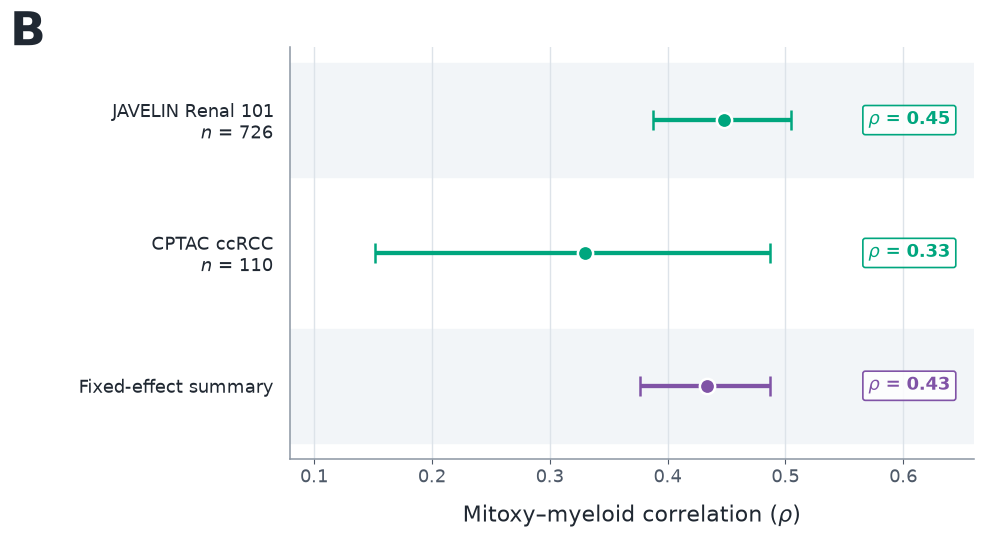

In [3]:
data = panel_b.iloc[::-1].reset_index(drop=True)
y = np.arange(len(data))
fig, ax = plt.subplots(figsize=(10.2, 5.8))
colors = [PURPLE, TEAL, TEAL]
for i in range(len(data)):
    if i % 2 == 0:
        ax.axhspan(i - 0.43, i + 0.43, color=BAND, zorder=0)
for i, (row, color) in enumerate(zip(data.itertuples(index=False), colors)):
    ax.errorbar(row.rho, i,
                xerr=[[row.rho-row.ci_low], [row.ci_high-row.rho]],
                fmt="o", color=color, ecolor=color, markersize=11,
                elinewidth=3.1, capsize=7, capthick=2,
                markeredgecolor=WHITE, markeredgewidth=1.8, zorder=3)
    ax.text(0.64, i, rf"$\rho$ = {row.rho:.2f}",
            ha="right", va="center", fontsize=12.7, fontweight="bold",
            color=color,
            bbox={"boxstyle":"round,pad=0.31,rounding_size=0.14",
                  "facecolor":(1,1,1,0.82), "edgecolor":color,
                  "linewidth":1.2})

labels = [
    "Fixed-effect summary",
    "CPTAC ccRCC\n$n$ = 110",
    "JAVELIN Renal 101\n$n$ = 726",
]
ax.set_yticks(y, labels, fontsize=13)
ax.axvline(0, color="#8B96A3", linestyle="--", linewidth=1.4)
ax.set_xlim(0.08, 0.66)
ax.set_ylim(-0.55, len(data)-0.45)
ax.set_xlabel(r"Mitoxy–myeloid correlation ($\rho$)", fontsize=16, labelpad=13)
ax.tick_params(axis="y", length=0, pad=12)
clean_axes(ax, "x")
panel_letter(fig, "B")
fig.subplots_adjust(left=0.30, right=0.97, top=0.90, bottom=0.19)
panel_b_paths = save_panel(fig, "figure_5b_cross_cohort_coupling")
plt.show()


## Panel C — covariate-adjusted coupling


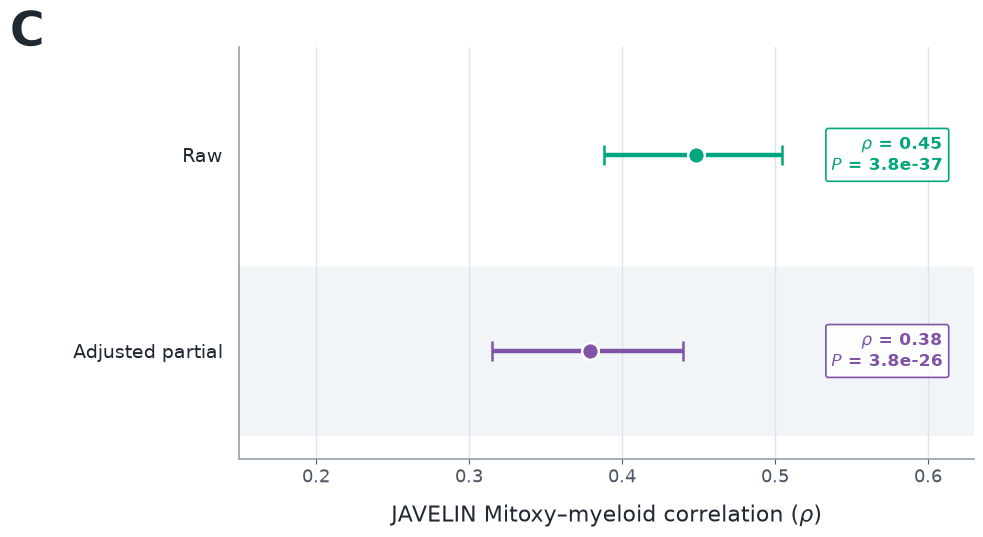

In [4]:
data = panel_c.iloc[::-1].reset_index(drop=True)
y = np.arange(len(data))
fig, ax = plt.subplots(figsize=(10.2, 5.8))
colors = [PURPLE, TEAL]
for i in range(len(data)):
    if i % 2 == 0:
        ax.axhspan(i - 0.43, i + 0.43, color=BAND, zorder=0)
for i, (row, color) in enumerate(zip(data.itertuples(index=False), colors)):
    ax.errorbar(row.rho, i,
                xerr=[[row.rho-row.ci_low], [row.ci_high-row.rho]],
                fmt="o", color=color, ecolor=color, markersize=12,
                elinewidth=3.2, capsize=7, capthick=2,
                markeredgecolor=WHITE, markeredgewidth=1.8, zorder=3)
    ax.text(0.61, i,
            rf"$\rho$ = {row.rho:.2f}" + "\n" + rf"$P$ = {p_text(row.p_value)}",
            ha="right", va="center", fontsize=12.6, fontweight="bold",
            color=color,
            bbox={"boxstyle":"round,pad=0.31,rounding_size=0.14",
                  "facecolor":(1,1,1,0.82), "edgecolor":color,
                  "linewidth":1.2})

ax.set_yticks(y, data["model"], fontsize=13.5)
ax.axvline(0, color="#8B96A3", linestyle="--", linewidth=1.4)
ax.set_xlim(0.15, 0.63)
ax.set_ylim(-0.55, len(data)-0.45)
ax.set_xlabel(r"JAVELIN Mitoxy–myeloid correlation ($\rho$)",
              fontsize=16, labelpad=13)
ax.tick_params(axis="y", length=0, pad=12)
clean_axes(ax, "x")
panel_letter(fig, "C")
fig.subplots_adjust(left=0.25, right=0.97, top=0.90, bottom=0.19)
panel_c_paths = save_panel(fig, "figure_5c_adjusted_coupling")
plt.show()


## Panel D — spatial replication


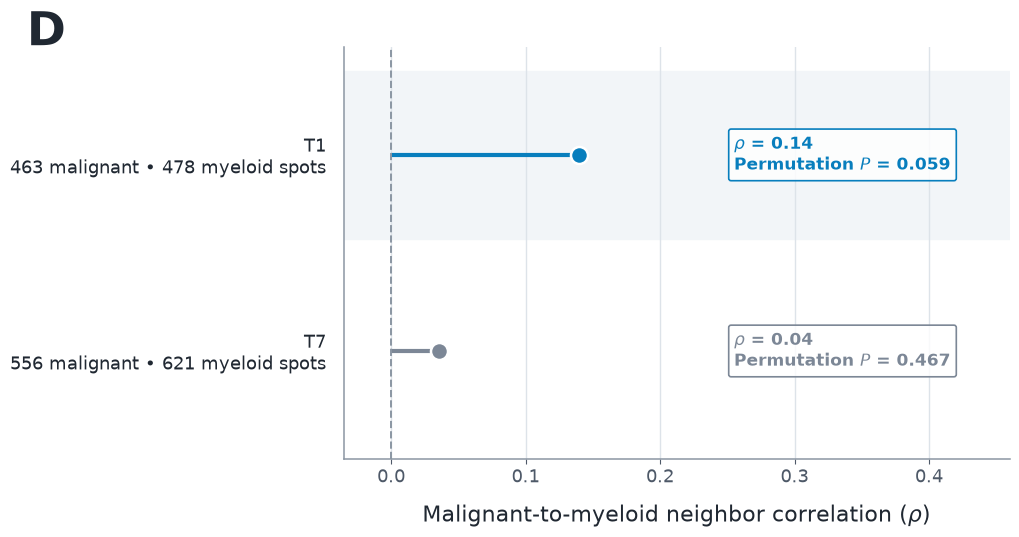

In [5]:
data = panel_d.iloc[::-1].reset_index(drop=True)
y = np.arange(len(data))
fig, ax = plt.subplots(figsize=(10.4, 5.8))
colors = ["#7C8796", BLUE]
for i in range(len(data)):
    if i % 2 == 1:
        ax.axhspan(i - 0.43, i + 0.43, color=BAND, zorder=0)
for i, (row, color) in enumerate(zip(data.itertuples(index=False), colors)):
    ax.hlines(i, 0, row.neighbor_rho, color=color, linewidth=3.0, zorder=2)
    ax.scatter(row.neighbor_rho, i, s=150, color=color, edgecolor=WHITE,
               linewidth=1.8, zorder=3)
    ax.text(0.255, i,
            rf"$\rho$ = {row.neighbor_rho:.2f}" + "\n" +
            rf"Permutation $P$ = {p_text(row.permutation_p)}",
            ha="left", va="center", fontsize=12.3, fontweight="bold",
            color=color,
            bbox={"boxstyle":"round,pad=0.31,rounding_size=0.14",
                  "facecolor":(1,1,1,0.82), "edgecolor":color,
                  "linewidth":1.2})

labels = [
    f"T7\n{int(data.loc[0, 'n_malignant'])} malignant • "
    f"{int(data.loc[0, 'n_myeloid'])} myeloid spots",
    f"T1\n{int(data.loc[1, 'n_malignant'])} malignant • "
    f"{int(data.loc[1, 'n_myeloid'])} myeloid spots",
]
ax.set_yticks(y, labels, fontsize=12.7)
ax.axvline(0, color="#8B96A3", linestyle="--", linewidth=1.4)
ax.set_xlim(-0.035, 0.46)
ax.set_ylim(-0.55, len(data)-0.45)
ax.set_xlabel(r"Malignant-to-myeloid neighbor correlation ($\rho$)",
              fontsize=16, labelpad=13)
ax.tick_params(axis="y", length=0, pad=13)
clean_axes(ax, "x")
panel_letter(fig, "D")
fig.subplots_adjust(left=0.33, right=0.97, top=0.90, bottom=0.19)
panel_d_paths = save_panel(fig, "figure_5d_spatial_replication")
plt.show()


## Assemble Figure 5


Saved:
/scratch/ar58064/mitoxy/figures/figure_5_clean/Figure_5_complete.png
/scratch/ar58064/mitoxy/figures/figure_5_clean/Figure_5_complete.tiff


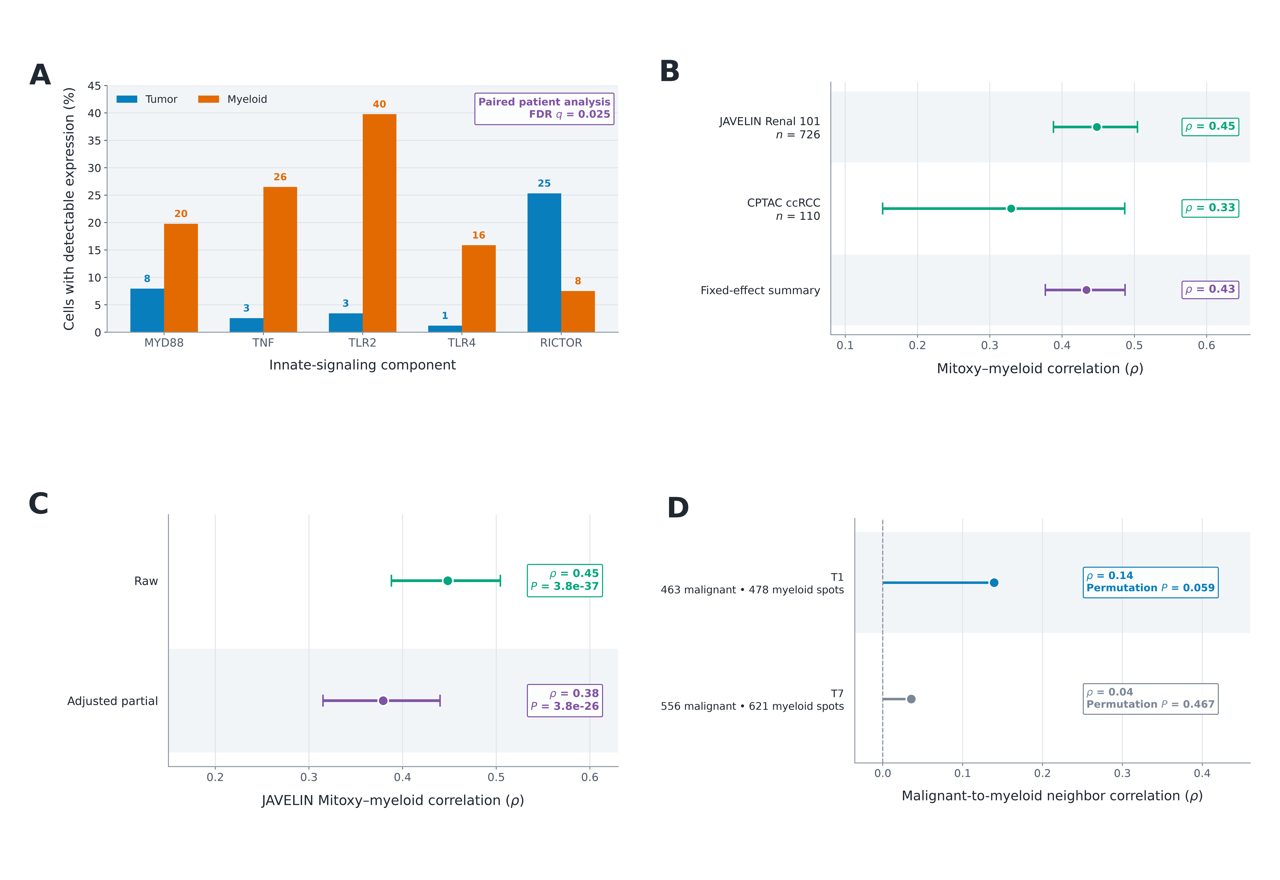

In [6]:
panel_paths = {
    "A": panel_a_paths["png"], "B": panel_b_paths["png"],
    "C": panel_c_paths["png"], "D": panel_d_paths["png"],
}

def trim_image(image, border=35):
    image = image.convert("RGB")
    background = PILImage.new("RGB", image.size, "white")
    box = ImageChops.difference(image, background).getbbox()
    if box is None:
        return image
    left, upper, right, lower = box
    return image.crop((
        max(0, left-border), max(0, upper-border),
        min(image.width, right+border), min(image.height, lower+border),
    ))

def place_contained(canvas, image_path, box):
    left, top, right, bottom = box
    image = trim_image(PILImage.open(image_path))
    image.thumbnail((right-left, bottom-top), PILImage.Resampling.LANCZOS)
    x = left + (right-left-image.width)//2
    y = top + (bottom-top-image.height)//2
    canvas.paste(image, (x, y))

canvas = PILImage.new("RGB", (6400, 4400), "white")
boxes = {
    "A": (120, 70, 3120, 2110),
    "B": (3280, 70, 6280, 2110),
    "C": (120, 2230, 3120, 4270),
    "D": (3280, 2230, 6280, 4270),
}
for letter, path in panel_paths.items():
    place_contained(canvas, path, boxes[letter])

final_png = FIGURE_DIR / "Figure_5_complete.png"
final_tiff = FIGURE_DIR / "Figure_5_complete.tiff"
canvas.save(final_png, dpi=(400, 400))
canvas.save(final_tiff, dpi=(400, 400), compression="tiff_lzw")
print("Saved:")
print(final_png)
print(final_tiff)
display(canvas.resize((1280, 880)))
